# Natural Language Processing Basics

Text is unstructured data. Before a model can use it, we must convert it into numbers. This notebook
covers the classic NLP pipeline that is still a strong baseline for many text classification tasks:

1. clean and normalise text,
2. tokenise it,
3. build a bag-of-words or TF-IDF representation,
4. train a linear classifier,
5. inspect the learned vocabulary weights.

## Learning objectives

1. Explain tokenisation, stop-word removal, and n-grams.
2. Compare bag-of-words and TF-IDF representations.
3. Train and evaluate a text classifier.
4. Interpret model coefficients as word importance.
5. Understand the limits of lexical models and when to use embeddings or transformers.

## 1. Concepts

### Preprocessing

- **Lowercasing** reduces vocabulary size but can lose meaning in some tasks.
- **Punctuation removal** simplifies tokens but may remove useful signals (`!`, `?`).
- **Tokenisation** splits text into words or subwords.
- **Stop-word removal** drops very common words; it helps some tasks and hurts others.
- **Stemming / lemmatisation** reduces inflected forms to a common base.
- **n-grams** capture short phrases such as "not good".

### Bag-of-words (BoW)

Each document becomes a vector of token counts. Word order is ignored. BoW is simple and often
surprisingly strong for topic and sentiment classification.

### TF-IDF

Term frequency-inverse document frequency downweights words that appear in many documents:

$$\text{tfidf}(t, d) = \text{tf}(t, d) \cdot \log\left(\frac{N}{1 + \text{df}(t)}\right)$$

Rare, discriminative words receive higher weights than common words.

### Limitations

BoW and TF-IDF do not understand synonyms, negation, sarcasm, or long-range context. Word embeddings
(Word2Vec, GloVe) and contextual models (BERT-like transformers) address some of these limits, at the
cost of more data and compute.

## 2. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. A small labelled sentiment corpus

The corpus is intentionally small so the notebook stays offline and fast. In a real project you would
use thousands of examples and a held-out, domain-matched test set.

In [2]:
positive = [
    "I love this product, it works perfectly",
    "Amazing quality and fast delivery",
    "The support team was helpful and friendly",
    "This is the best purchase I have made this year",
    "Excellent value for the price",
    "The app is simple, fast, and reliable",
    "I am very happy with the results",
    "Great experience from start to finish",
    "The update fixed all my problems",
    "Fantastic design and solid build",
    "Works exactly as advertised",
    "Highly recommended, would buy again",
    "The instructions were clear and easy to follow",
    "Fantastic customer service and quick response",
    "This saved me hours of work",
    "The quality exceeded my expectations",
    "Very intuitive and pleasant to use",
    "I am impressed with the performance",
    "The new feature is incredibly useful",
    "Reliable, affordable, and well made",
    "The team did an outstanding job",
    "Setup was quick and painless",
    "The battery life is excellent",
    "A joy to use every day",
    "The documentation is clear and complete",
    "Great balance between price and quality",
    "The product feels premium and durable",
    "I received it earlier than expected",
    "The interface is clean and modern",
    "Everything worked on the first try",
    "Support resolved my issue in minutes",
    "This is a significant improvement",
    "The results are accurate and consistent",
    "I would happily recommend this to a friend",
    "The experience was smooth and stress free",
    "It exceeded the specifications",
    "Very satisfied with the overall quality",
    "The design is thoughtful and practical",
    "Fast, efficient, and dependable",
    "A great addition to my workflow",
]

negative = [
    "I hate this product, it never works",
    "Terrible quality and very slow delivery",
    "The support team ignored my messages",
    "This is the worst purchase I have made",
    "A complete waste of money",
    "The app crashes constantly and feels slow",
    "I am very disappointed with the results",
    "Bad experience from start to finish",
    "The update broke everything",
    "Poor design and cheap materials",
    "Does not work as advertised",
    "Would not recommend this to anyone",
    "The instructions were confusing and incomplete",
    "Support was rude and unhelpful",
    "This created hours of extra work",
    "The quality was far below my expectations",
    "Confusing and frustrating to use",
    "I am unhappy with the performance",
    "The new feature is completely useless",
    "Unreliable, overpriced, and poorly made",
    "The team did a careless job",
    "Setup failed twice and took all day",
    "The battery drains within an hour",
    "A painful experience every time",
    "The documentation is outdated and wrong",
    "Bad value for the price",
    "The product feels cheap and fragile",
    "It arrived late and damaged",
    "The interface is cluttered and slow",
    "Nothing worked on the first try",
    "Support never solved my issue",
    "This is a major regression",
    "The results are inaccurate and inconsistent",
    "I would never recommend this to a friend",
    "The experience was stressful and slow",
    "It failed to meet the specifications",
    "Very dissatisfied with the overall quality",
    "The design is impractical and awkward",
    "Slow, buggy, and unreliable",
    "A waste of time and effort",
]

texts = positive + negative
labels = [1] * len(positive) + [0] * len(negative)
df = pd.DataFrame({"text": texts, "label": labels}).sample(frac=1, random_state=RANDOM_STATE).reset_index(drop=True)

print(df.shape)
print(df["label"].value_counts())
df.head()

(80, 2)
label
1    40
0    40
Name: count, dtype: int64


,text,label
0,Support resolved my issue in minutes,1
1,"I love this product, it works perfectly",1
2,The battery life is excellent,1
3,This is a significant improvement,1
4,The new feature is incredibly useful,1


## 4. Text cleaning

We use a small, dependency-free cleaner. In production, consider `spaCy`, `NLTK`, or a tokeniser that
matches your language and domain.

In [3]:
STOPWORDS = {
    "a", "an", "and", "are", "as", "at", "be", "but", "by", "for", "from",
    "had", "has", "have", "he", "her", "his", "i", "in", "is", "it", "its",
    "my", "of", "on", "or", "our", "she", "that", "the", "their", "them",
    "this", "to", "was", "we", "were", "with", "you", "your", "would",
}

def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    tokens = text.split()
    tokens = [token for token in tokens if token not in STOPWORDS and len(token) > 1]
    return " ".join(tokens)

df["clean"] = df["text"].apply(clean_text)
df[["text", "clean"]].head()

,text,clean
0,Support resolved my issue in minutes,support resolved issue minutes
1,"I love this product, it works perfectly",love product works perfectly
2,The battery life is excellent,battery life excellent
3,This is a significant improvement,significant improvement
4,The new feature is incredibly useful,new feature incredibly useful


## 5. Train/test split

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    df["clean"], df["label"], test_size=0.25, random_state=RANDOM_STATE, stratify=df["label"]
)
print(len(X_train), len(X_test))

60 20


## 6. Bag-of-words vs TF-IDF

We compare unigrams and unigrams plus bigrams for both representations.

In [5]:
def evaluate_vectorizer(name, vectorizer, classifier=None):
    classifier = classifier or LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)
    X_train_vec = vectorizer.fit_transform(X_train)
    X_test_vec = vectorizer.transform(X_test)
    classifier.fit(X_train_vec, y_train)
    pred = classifier.predict(X_test_vec)
    return {
        "representation": name,
        "vocabulary_size": len(vectorizer.get_feature_names_out()),
        "accuracy": accuracy_score(y_test, pred),
        "classifier": classifier,
        "vectorizer": vectorizer,
    }

experiments = [
    evaluate_vectorizer("BoW unigram", CountVectorizer(ngram_range=(1, 1))),
    evaluate_vectorizer("BoW unigram+bigram", CountVectorizer(ngram_range=(1, 2))),
    evaluate_vectorizer("TF-IDF unigram", TfidfVectorizer(ngram_range=(1, 1))),
    evaluate_vectorizer("TF-IDF unigram+bigram", TfidfVectorizer(ngram_range=(1, 2))),
]

pd.DataFrame([
    {"representation": e["representation"], "vocabulary_size": e["vocabulary_size"], "accuracy": e["accuracy"]}
    for e in experiments
]).round(4)

,representation,vocabulary_size,accuracy
0,BoW unigram,148,0.45
1,BoW unigram+bigram,298,0.35
2,TF-IDF unigram,148,0.40
3,TF-IDF unigram+bigram,298,0.35


## 7. Inspect the best model

Coefficients from a linear classifier indicate which words push predictions toward positive or
negative sentiment. This is a useful sanity check, not a causal explanation.

In [6]:
best = max(experiments, key=lambda e: e["accuracy"])
print("Best representation:", best["representation"], "accuracy:", round(best["accuracy"], 4))

feature_names = best["vectorizer"].get_feature_names_out()
coefficients = best["classifier"].coef_[0]
weights = pd.DataFrame({"token": feature_names, "coefficient": coefficients})
weights = weights.sort_values("coefficient")

top_negative = weights.head(10)
top_positive = weights.tail(10).iloc[::-1]
pd.concat([top_positive, top_negative]).reset_index(drop=True)

Best representation: BoW unigram accuracy: 0.45


,token,coefficient
0,fast,0.668571
1,great,0.663194
2,excellent,0.610554
3,use,0.563230
4,exceeded,0.561603
5,quick,0.472220
6,fantastic,0.443287
7,impressed,0.426764
8,happily,0.401128
9,friendly,0.379696


              precision    recall  f1-score   support

    negative       0.43      0.30      0.35        10
    positive       0.46      0.60      0.52        10

    accuracy                           0.45        20
   macro avg       0.45      0.45      0.44        20
weighted avg       0.45      0.45      0.44        20



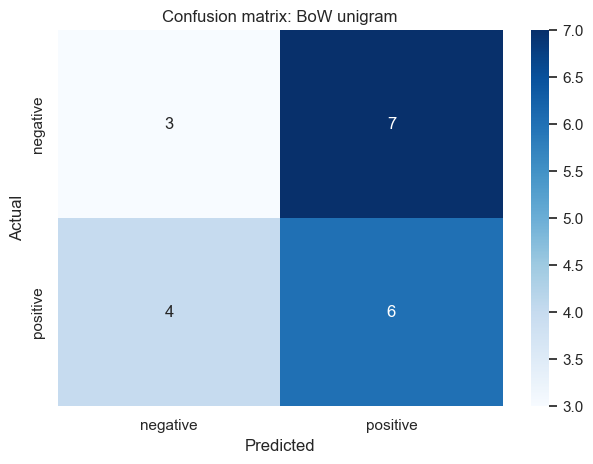

In [7]:
pred = best["classifier"].predict(best["vectorizer"].transform(X_test))
print(classification_report(y_test, pred, target_names=["negative", "positive"]))

cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["negative", "positive"], yticklabels=["negative", "positive"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title(f"Confusion matrix: {best['representation']}")
plt.tight_layout()
plt.show()

## 8. Predict new text

In [8]:
def predict_sentiment(text):
    cleaned = clean_text(text)
    vector = best["vectorizer"].transform([cleaned])
    probability = best["classifier"].predict_proba(vector)[0, 1]
    label = "positive" if probability >= 0.5 else "negative"
    return label, round(float(probability), 4)

for sentence in [
    "This product is fantastic and works perfectly",
    "The app is slow and crashes constantly",
    "The delivery was late but the quality is great",
]:
    print(sentence, "->", predict_sentiment(sentence))

This product is fantastic and works perfectly -> ('positive', 0.6513)
The app is slow and crashes constantly -> ('negative', 0.197)
The delivery was late but the quality is great -> ('positive', 0.688)


## 9. Where lexical models fail

- **Negation**: "not good" contains "good"; bigrams help but do not solve the problem.
- **Sarcasm**: "Great, it broke again" is negative.
- **Synonyms**: "excellent" and "superb" are separate tokens in BoW.
- **Context**: "The plot was predictable" depends on the review domain.
- **Domain shift**: a model trained on product reviews may fail on clinical notes.

Embeddings and transformers address some of these issues, but they require more data, compute, and
careful evaluation.

## Key takeaways

- Clean and tokenise text before vectorising.
- BoW and TF-IDF are strong, fast baselines.
- Bigrams capture short phrases and often improve sentiment models.
- Inspect coefficients for sanity, not causality.
- Use a held-out, domain-matched test set; accuracy on a tiny corpus is not a production estimate.

## Exercises

1. Add trigrams and compare accuracy and vocabulary size.
2. Implement negation handling by prefixing "not_" to the token after "not".
3. Try `MultinomialNB` and compare it with logistic regression.
4. Use `TfidfVectorizer(sublinear_tf=True)` and compare results.
5. Collect a larger labelled dataset and measure how the conclusions change.
6. Read about word embeddings and explain how they solve the synonym problem.